# Lab 3.6 · ONNX Runtime and TensorRT

**15–20 minutes · CPU**

Follow the [lab guide](README.md) for setup. Run the setup cell, make a prediction for each exercise, replace each `return None`, and run its check.

An ONNX export describes a graph contract: input names, dtypes, shapes, and operators. ONNX Runtime executes the graph with an execution provider. TensorRT can build a device-specific engine from a compatible graph. Dynamic dimensions in a TensorRT engine need a build profile, with min, optimum and max shapes.

This lab exports a small PyTorch model with a symbolic batch dimension. Run it through ONNX Runtime on CPU and compare two batch sizes. A successful export checks representability. Numerical parity still needs to be tested.

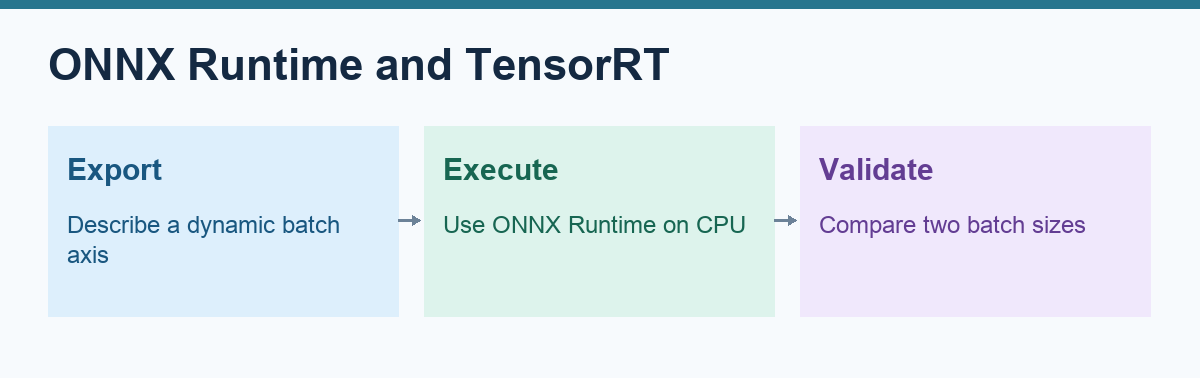

## Exercise map

| Exercise | What you will do | What to look for |
| --- | --- | --- |
| 1. Export a dynamic graph | Write the model to BytesIO using torch.onnx.export. Name the input x and output y. Mark axis zero as batch for both and use opset 17. Return the bytes. | A symbolic batch dimension allows the same graph to accept different numbers of input rows. |
| 2. Verify numerical parity | Create a CPUExecutionProvider session from the bytes, run output y with input x, and return the output array. | Parity across shapes is evidence that the dynamic contract works for the cases you tested. |

In [ ]:
from io import BytesIO
import numpy as np
import onnx
import onnxruntime as ort
import torch
from torch import nn

torch.manual_seed(7)
model = nn.Sequential(nn.Linear(4, 3), nn.ReLU()).eval()
example = torch.randn(1, 4)

## Exercise 1. Export a dynamic graph

Write the model to BytesIO using torch.onnx.export. Name the input x and output y. Mark axis zero as batch for both and use opset 17. Return the bytes.

In [ ]:
def export_model(model, example):
    return None

In [ ]:
graph_bytes = export_model(model, example)
if graph_bytes is not None:
    graph = onnx.load_model_from_string(graph_bytes)
    onnx.checker.check_model(graph)
    assert graph.graph.input[0].name == "x"
    assert graph.graph.input[0].type.tensor_type.shape.dim[0].dim_param == "batch"
    print("PASS — graph operators:", [node.op_type for node in graph.graph.node])

### Read the result

A symbolic batch dimension allows the same graph to accept different numbers of input rows.

## Exercise 2. Verify numerical parity

Create a CPUExecutionProvider session from the bytes, run output y with input x, and return the output array.

In [ ]:
def run_onnx(graph_bytes, inputs):
    return None

In [ ]:
if graph_bytes is not None:
    for batch in (1, 4):
        x = torch.randn(batch, 4)
        result = run_onnx(graph_bytes, x.numpy())
        if result is None:
            print("Complete run_onnx.")
            break
        with torch.inference_mode():
            expected = model(x).numpy()
        assert result.shape == (batch, 3)
        np.testing.assert_allclose(result, expected, rtol=1e-5, atol=1e-6)
    else:
        print("PASS — ONNX Runtime matches PyTorch for both batch sizes")

### Read the result

Parity across shapes is evidence that the dynamic contract works for the cases you tested.

## Optional extension

On a compatible NVIDIA TensorRT host, write the completed export with `Path('lab-model.onnx').write_bytes(graph_bytes)` after importing Path. Build an engine with `trtexec --onnx=lab-model.onnx --minShapes=x:1x4 --optShapes=x:4x4 --maxShapes=x:8x4 --saveEngine=lab-model.plan`. Then run `trtexec --loadEngine=lab-model.plan --shapes=x:4x4`. The optional TensorRT commands require a compatible GPU and installation. Compare engine build time and steady-state execution separately.

## Reading

Philip Kiely, *Inference Engineering*, §4.2.3, pp. 104–105.

- [PyTorch ONNX export](https://docs.pytorch.org/docs/stable/onnx)
- [ONNX Runtime Python API](https://onnxruntime.ai/docs/api/python/api_summary.html)
- [NVIDIA TensorRT engine guide](https://docs.nvidia.com/deeplearning/tensorrt/latest/getting-started/build-your-first-engine.html)